# 35 - Qualidade da água: o que é fiável e o que não é

| | |
|---|---|
| **Tarefa do plano** | Validação da componente de qualidade da água (variáveis #51 e #52) |
| **O que faz** | Testa a sério os indicadores de turbidez: dois satélites independentes, um método em unidades reais, modelos de previsão |
| **Usa** | Séries imagem a imagem do Sentinel-2 (2017–2026) e do Landsat 8/9 (2013–2026), extraídas com `scripts/update_water_quality_scenes.py`; histórico de caudal e chuva |
| **Produz** | `models/modelo_turbidez.joblib`, `models/mare_maputo.json`, `models/turbidez_por_caudal.json`, tabelas e figuras em `reports/semana_3/` |

O notebook 34 construiu um indicador mensal. Este notebook responde a uma
pergunta mais exigente: **o que disto se pode mostrar a um público internacional
sem que um especialista o desmonte?** São feitos sete testes, e três deles
falham. Os que falham ficam aqui documentados, como a harmonização do Landsat.

| Teste | Pergunta | Resultado |
|---|---|---|
| 1 | A turbidez em unidades reais (FNU), por um método publicado, é repetível entre satélites? | **Não.** Rejeitada |
| 2 | O índice de cor NDTI é repetível entre satélites? | **Sim** |
| 3 | A turbidez acompanha o caudal? | **Sim**, de forma clara |
| 4 | Um modelo de IA só com caudal, chuva e época do ano prevê a turbidez? | **Não** |
| 5 | Juntando a maré, o modelo passa a prever? | **Sim** |
| 6 | A maré completa e a última medição por satélite melhoram a previsão? | **Sim** |
| 7 | Vento, chuva local, chuva por parte da bacia, treinar com os dois satélites? | **Não** melhoram: ficam de fora |

**Porque dois satélites.** Não há medições de turbidez feitas no Incomáti. A
melhor prova disponível é comparar dois instrumentos independentes: o Sentinel-2
(europeu) e o Landsat 8/9 (americano) têm sensores diferentes e correções
atmosféricas diferentes. Se, no mesmo dia e no mesmo troço, derem o mesmo valor,
a medição é repetível. Não prova que o valor esteja certo em absoluto, mas é a
condição mínima para ser levado a sério.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, rasters
from ete import grid as G
from ete import models as M

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

import json

from ete import forecast, forecast_models
from ete import water_quality as W

## 1. Os dados: uma medição por imagem

Em vez da mediana do mês, cada imagem de satélite dá uma medição por troço: a
mediana dos píxeis de água aberta, depois de retirar nuvens, bruma, reflexos do
sol e plantas flutuantes. Um troço só conta num dia se pelo menos um quarto dele
foi visto limpo.

Sentinel-2 : 814 dias com medição, 2017-01-06 a 2026-10-09
Landsat 8/9: 270 dias com medição, 2013-04-07 a 2026-10-03


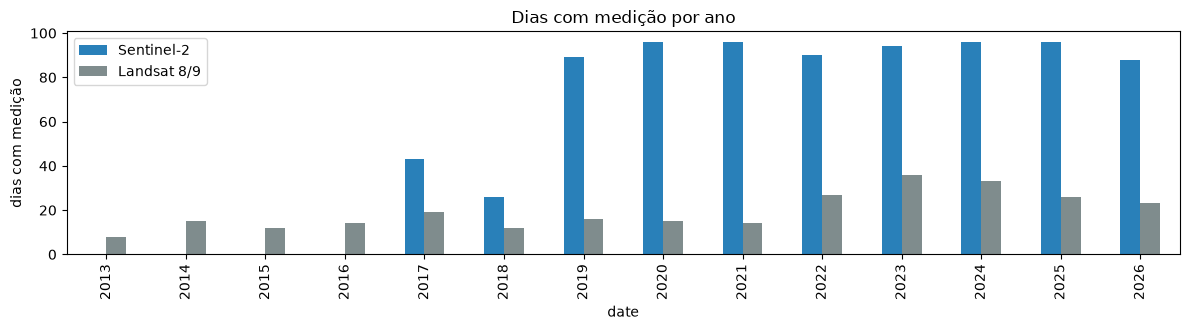

In [2]:
s2, ls = W.load_scene_series(cfg, "sentinel2"), W.load_scene_series(cfg, "landsat89")
print(f"Sentinel-2 : {s2['date'].nunique()} dias com medição, {s2['date'].min().date()} a {s2['date'].max().date()}")
print(f"Landsat 8/9: {ls['date'].nunique()} dias com medição, {ls['date'].min().date()} a {ls['date'].max().date()}")
per_year = pd.DataFrame({"Sentinel-2": s2.groupby(s2["date"].dt.year)["date"].nunique(), "Landsat 8/9": ls.groupby(ls["date"].dt.year)["date"].nunique()}).fillna(0).astype(int)
ax = per_year.plot.bar(figsize=(12, 3.4), color=["#2980b9", "#7f8c8d"], ylabel="dias com medição", title="Dias com medição por ano")
plt.tight_layout(); plt.savefig(REPORTS / "35_dias_com_medicao.png", dpi=110)

## 2. Teste 1: turbidez em unidades reais (FNU). Rejeitada

Método de Dogliotti et al. (2011): turbidez = A × ρ / (1 − ρ / C), com a
refletância ρ no infravermelho próximo (cerca de 860 nm), A = 3078,9 FNU e
C = 0,211. Os coeficientes foram conferidos na tabela 2 do artigo original. É um
método usado em estuários muito turvos de todo o mundo.

A comparação junta as medições dos dois satélites feitas com um dia de diferença
no máximo, no mesmo troço.

674 pares | correlação 0.21 | os dois satélites diferem tipicamente por um fator de 6.6
correlação da refletância no infravermelho próximo entre satélites: 0.40


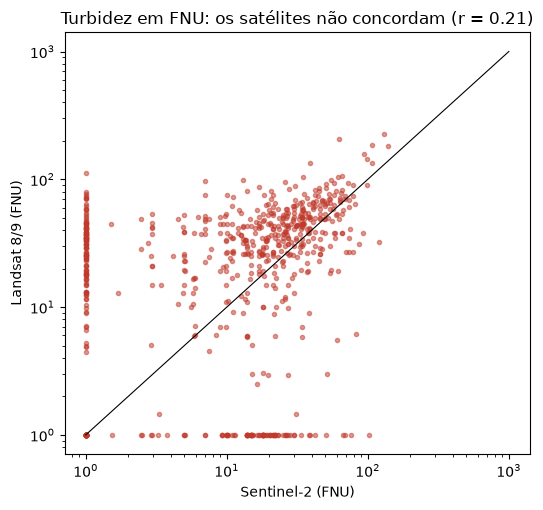

In [3]:
pairs = W.cross_sensor_pairs(s2, ls, max_days=1)
fnu = W.log_agreement(pairs["turbidez_fnu_s2"], pairs["turbidez_fnu_landsat"])
nir_r = np.corrcoef(pairs["nir_s2"], pairs["nir_landsat"])[0, 1]
print(f"{fnu['n']} pares | correlação {fnu['r']:.2f} | os dois satélites diferem tipicamente por um fator de {fnu['fator_tipico']:.1f}")
print(f"correlação da refletância no infravermelho próximo entre satélites: {nir_r:.2f}")

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.loglog(pairs["turbidez_fnu_s2"].clip(lower=1), pairs["turbidez_fnu_landsat"].clip(lower=1), ".", color="#c0392b", alpha=0.5)
ax.plot([1, 1000], [1, 1000], color="black", linewidth=0.8); ax.set_xlabel("Sentinel-2 (FNU)"); ax.set_ylabel("Landsat 8/9 (FNU)")
ax.set_title(f"Turbidez em FNU: os satélites não concordam (r = {fnu['r']:.2f})")
plt.tight_layout(); plt.savefig(REPORTS / "35_fnu_entre_satelites.png", dpi=110)

**Leitura.** Os pontos deviam estar sobre a linha. Não estão: o mesmo troço, no
mesmo dia, dá valores que diferem várias vezes entre os dois satélites.

**Porquê.** A água reflete muito pouco no infravermelho próximo. Num rio estreito
entre margens com vegetação, o que o satélite mede aí é sobretudo luz das margens
espalhada pela atmosfera e erro da correção atmosférica, não o sedimento. O
método funciona em estuários largos e muito turvos; no Incomáti, com estas
imagens, não.

**Decisão: a plataforma não mostra turbidez em FNU.** Um número com unidades dá
uma impressão de exatidão que os dados não sustentam.

## 3. Teste 2: o índice de cor NDTI. Aprovado

NDTI = (vermelho − verde) / (vermelho + verde). É uma razão entre duas bandas
do visível, onde a água reflete bem. Os erros que afetam as duas bandas por
igual anulam-se na divisão.

,pares,correlação,diferença_média,diferença_típica
"todos os troços, mesmo dia",261.000,0.920,-0.012,0.042
1 montante (norte),160.000,0.647,-0.002,0.045
2 troço médio,167.000,0.901,-0.006,0.034
3 jusante,172.000,0.892,-0.004,0.044
4 foz / estuário,175.000,0.856,-0.016,0.062


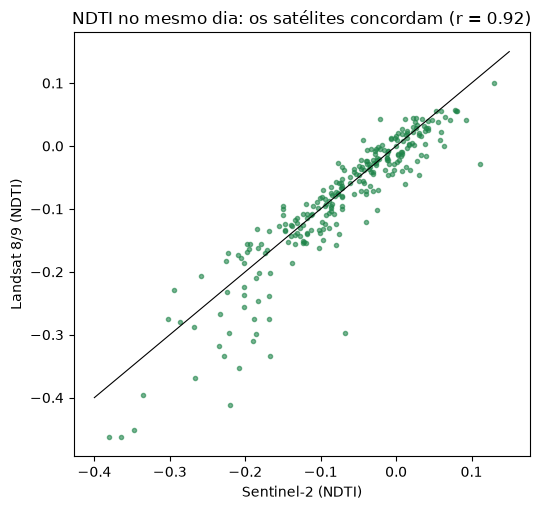

In [4]:
same_day = W.cross_sensor_pairs(s2, ls, max_days=0)
stats = lambda g: pd.Series({"pares": len(g), "correlação": np.corrcoef(g["ndti_s2"], g["ndti_landsat"])[0, 1],
                             "diferença_média": (g["ndti_landsat"] - g["ndti_s2"]).mean(),
                             "diferença_típica": np.sqrt(((g["ndti_landsat"] - g["ndti_s2"]) ** 2).mean())})
agreement = pd.concat([stats(same_day).to_frame("todos os troços, mesmo dia").T, pairs.groupby("troco").apply(stats, include_groups=False)])
agreement.round(3).to_csv(REPORTS / "35_ndti_entre_satelites.csv")

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.plot(same_day["ndti_s2"], same_day["ndti_landsat"], ".", color="#1e8449", alpha=0.6)
ax.plot([-0.4, 0.15], [-0.4, 0.15], color="black", linewidth=0.8); ax.set_xlabel("Sentinel-2 (NDTI)"); ax.set_ylabel("Landsat 8/9 (NDTI)")
ax.set_title(f"NDTI no mesmo dia: os satélites concordam (r = {agreement.iloc[0]['correlação']:.2f})")
plt.tight_layout(); plt.savefig(REPORTS / "35_ndti_entre_satelites.png", dpi=110)
agreement.round(3)

**Leitura.** Dois satélites independentes dão praticamente o mesmo NDTI no mesmo
dia, sem desvio sistemático entre eles. A medição é repetível.

**Uma exceção:** no troço 1 (montante), o mais estreito, a concordância é mais
fraca. As medições desse troço são marcadas na plataforma como de fiabilidade
reduzida, e ele fica fora das contas seguintes.

**O que este teste não prova:** que o NDTI corresponda a tantas unidades de
turbidez. Isso só com amostras recolhidas no rio.

## 4. Teste 3: a turbidez acompanha o caudal. Aprovado

Para cada classe de caudal: em que parte dos dias medidos a turbidez esteve
"elevada" (entre os 25 % de dias mais turvos desse troço). As barras de erro são
o intervalo de 90 %: quanto menos dias, maior a incerteza.

,dias_medidos,turbidez_elevada,intervalo_min,intervalo_max
caudal_m3s,,,,
abaixo de 20,1415,0.140,0.120,0.150
20 a 60,339,0.360,0.320,0.410
60 a 164,265,0.410,0.360,0.460
164 a 376 (amarelo),139,0.600,0.530,0.670
acima de 376 (laranja ou mais),56,0.790,0.680,0.860


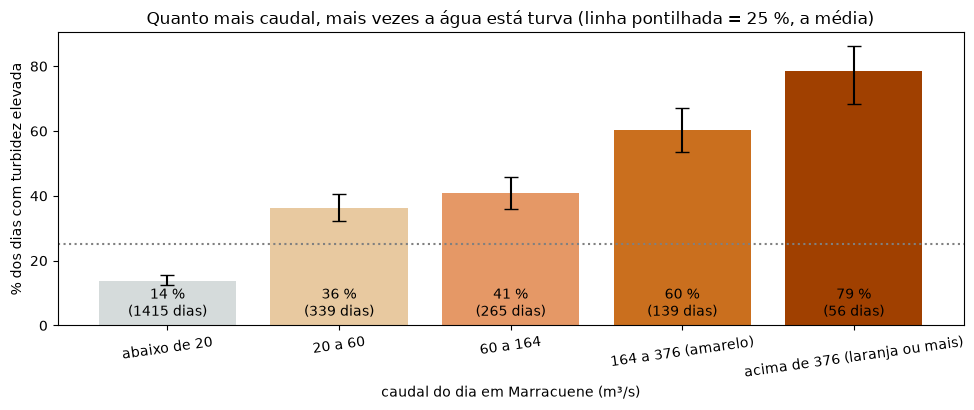

In [5]:
table, skill, days = forecast_models.fit_turbidity_table(cfg)
table.round(3).to_csv(REPORTS / "35_turbidez_por_caudal.csv")
skill.round(3).to_csv(REPORTS / "35_turbidez_por_caudal_desempenho.csv")

fig, ax = plt.subplots(figsize=(10, 4.2))
share = 100 * table["turbidez_elevada"]
ax.bar(range(len(table)), share, color=["#d5dbdb", "#e8c9a0", "#e59866", "#ca6f1e", "#a04000"],
       yerr=[share - 100 * table["intervalo_min"], 100 * table["intervalo_max"] - share], capsize=5)
for i, (v, n) in enumerate(zip(share, table["dias_medidos"])):
    ax.text(i, 3, f"{v:.0f} %\n({n} dias)", ha="center", fontsize=10)
ax.axhline(25, color="grey", linestyle=":"); ax.set_xticks(range(len(table)), table.index, rotation=8)
ax.set_ylabel("% dos dias com turbidez elevada"); ax.set_xlabel("caudal do dia em Marracuene (m³/s)")
ax.set_title("Quanto mais caudal, mais vezes a água está turva (linha pontilhada = 25 %, a média)")
plt.tight_layout(); plt.savefig(REPORTS / "35_turbidez_por_caudal.png", dpi=110)
table.round(2)

**Leitura.** A relação é clara e sobe sempre: com o rio baixo, a água raramente
está turva; com o caudal no nível laranja, está turva na grande maioria dos dias
medidos. É física simples (mais água arrasta mais sedimento) e os dados
confirmam-na.

É esta tabela que a plataforma usa para dizer o que esperar da turbidez quando
há previsão de caudal alto.

## 5. Teste 4: um modelo de IA sem a maré. Não chega

Um modelo de gradient boosting com o caudal de hoje e dos últimos dias, a chuva
acumulada e a época do ano, comparado com duas previsões simples. Cada ano é
previsto por um modelo que nunca o viu.

In [6]:
benchmark = forecast_models.turbidity_ml_benchmark(cfg)
benchmark.round(3).to_csv(REPORTS / "35_turbidez_modelo_de_ia.csv")
display(benchmark.round(3))
skill.round(3)

,dias,r2,mae
previsao,,,
modelo de IA (gradient boosting),2211,0.221,0.069
referência: época do ano,2211,0.207,0.070
referência: reta sobre o caudal,2211,0.229,0.069
"modelo de IA, dias do Landsat antes de 2017",128,0.271,0.099


,dias,auc,brier,bss
previsao,,,,
tabela por caudal (ano deixado de fora),2214,0.643,0.164,0.036
referência: época do ano,2214,0.696,0.170,NaN
"tabela, dias do Landsat antes de 2017",128,0.765,0.145,NaN


**Leitura honesta**

- O modelo de IA explica pouco mais da variação do NDTI do que a simples média
  do mês. A diferença não justifica um modelo mais complexo, e não melhora
  quando testado noutro satélite e noutros anos.
- A segunda tabela mostra o mesmo para a pergunta "vai estar elevada?": a tabela
  por caudal e a época do ano têm desempenhos próximos (`bss` perto de zero).
- A turbidez de um dia concreto depende de coisas que estes dados não veem:
  onde choveu, descargas de barragens, marés na foz, dragagens, vento. Nos
  troços de jusante e da foz, o valor muda bastante de uma imagem para a
  seguinte mesmo com o caudal estável, o que aponta para a maré. Por isso a
  plataforma mostra a mediana de várias imagens e não uma imagem isolada.

**Conclusão deste teste:** com caudal, chuva e época do ano não chega. Falta
uma causa. A secção seguinte testa a mais provável.

## 6. Teste 5: a maré. Aprovado

Nos troços de jusante e da foz, a cor da água muda muito de uma imagem para a
seguinte com o caudal estável. A hipótese: a maré. Quando a maré enche e vaza,
levanta sedimento do fundo e empurra água do estuário rio acima.

A fase da maré principal (a componente lunar M2, com período de 12,42 horas) é
conhecida com exatidão para qualquer momento, passado ou futuro, só a partir da
data e da hora. O gráfico mostra o índice de
cor de cada imagem contra a fase da maré à hora em que foi tirada.

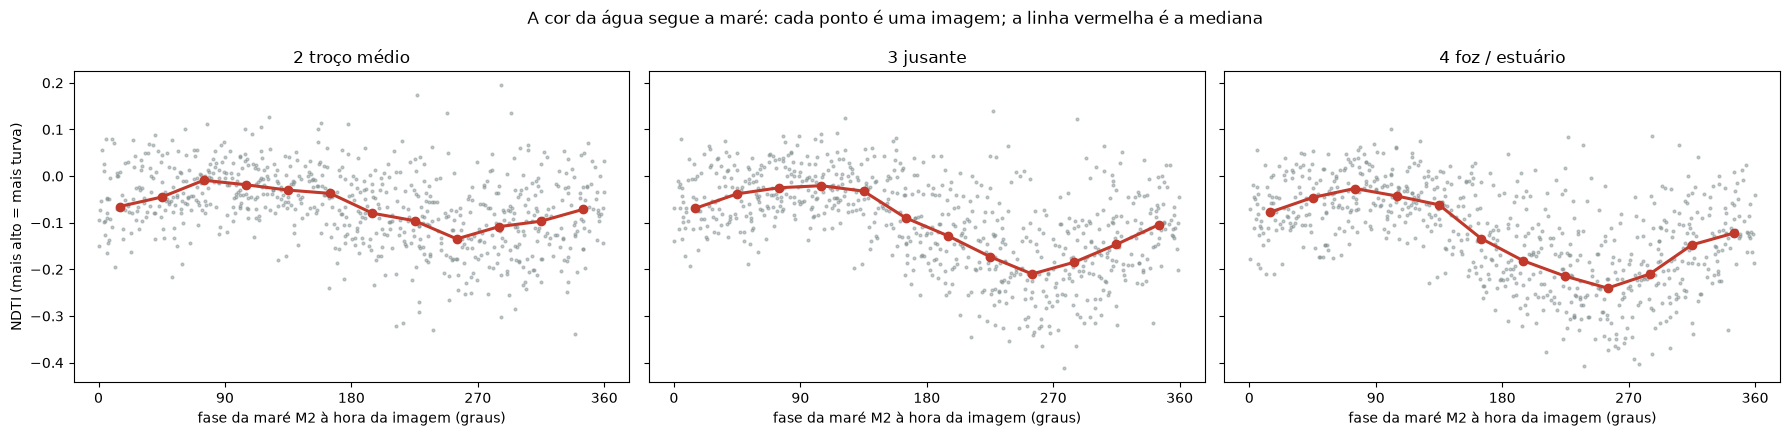

In [7]:
skill, days, other = forecast_models.fit_turbidity_model(cfg)
skill.round(3).to_csv(REPORTS / "35_modelo_com_mare.csv")

phase = (np.degrees(np.arctan2(days["m2_sin"], days["m2_cos"])) + 360) % 360
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), sharey=True)
for ax, (reach, g) in zip(axes, days.groupby("troco")):
    ax.plot(phase[g.index], g["ndti"], ".", color="#7f8c8d", alpha=0.45, markersize=4)
    binned = g.groupby(pd.cut(phase[g.index], np.arange(0, 361, 30)), observed=True)["ndti"].median()
    ax.plot([i.mid for i in binned.index], binned, color="#c0392b", linewidth=2.2, marker="o")
    ax.set_title(reach); ax.set_xlabel("fase da maré M2 à hora da imagem (graus)"); ax.set_xticks(range(0, 361, 90))
axes[0].set_ylabel("NDTI (mais alto = mais turva)")
plt.suptitle("A cor da água segue a maré: cada ponto é uma imagem; a linha vermelha é a mediana"); plt.tight_layout()
plt.savefig(REPORTS / "35_ndti_e_mare.png", dpi=110)

**Leitura.** A linha vermelha desenha uma onda: a turbidez sobe e desce com a fase
da maré. A onda é maior na foz e no troço de jusante e menor no troço médio,
exatamente o que se espera de um efeito de maré, que se atenua rio acima.

Só a fase da maré já faz o modelo passar de 0,19 para 0,60 de variação explicada
(tabela mais abaixo, linhas "sem maré" e "maré só pela fase M2").

## 7. Teste 6: maré completa e última medição. Aprovado

Dois aperfeiçoamentos, cada um testado em separado antes de entrar:

- **Maré completa.** Em vez de uma só componente, a maré é calculada com 22
  componentes, ajustadas ao nível do mar hora a hora na Baía de Maputo (serviço
  Open-Meteo, 2023 a 2026). O modelo passa a conhecer a altura da maré, se está a
  encher ou a vazar, e se é maré viva ou maré morta.
- **Última medição.** O que o modelo não explica num dia tende a repetir-se nos
  dias e semanas seguintes. Por isso o modelo recebe também a última medição por
  satélite desse troço (do Sentinel-2 ou do Landsat) e a idade dela.

maré calculada contra o nível do mar dos últimos 12 meses (não usados no ajuste): R² = 0.987, erro típico = 7 cm


troco,2 troço médio,3 jusante,4 foz / estuário
dias_antes,,,
2,0.660,0.500,0.430
3,0.520,0.440,0.350
5,0.520,0.400,0.360
10,0.410,0.290,0.250
15,0.530,0.350,0.320
20,0.340,0.200,0.180
30,0.400,0.290,0.310


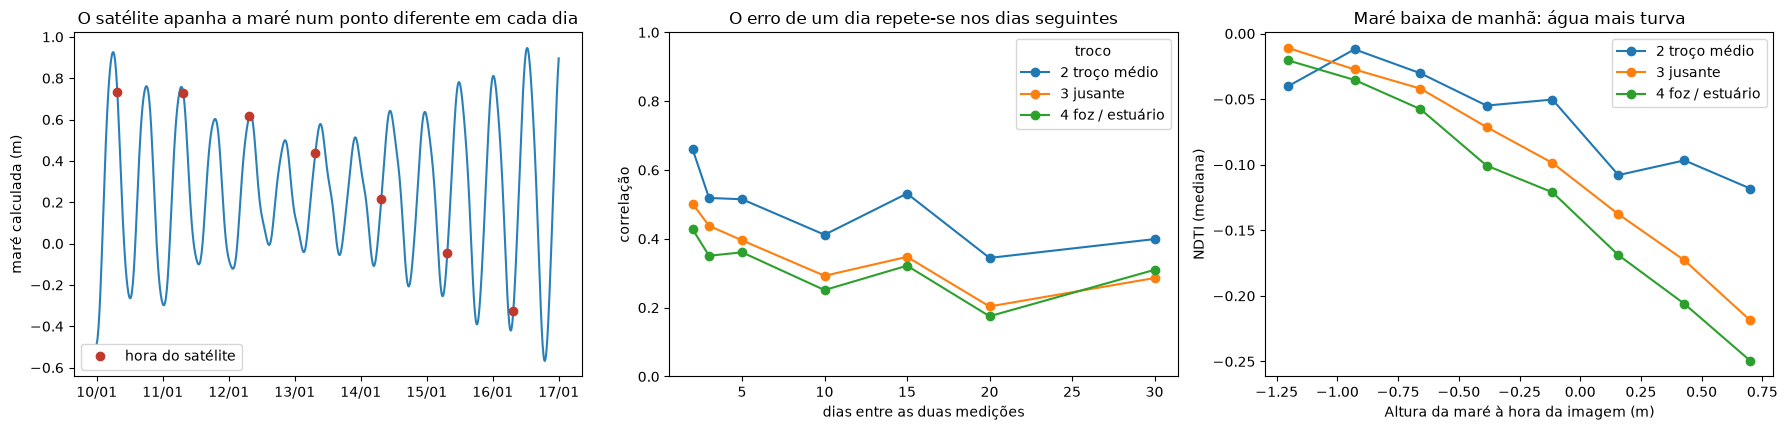

In [8]:
tide = json.loads((ROOT / "models" / "mare_maputo.json").read_text())
print(f"maré calculada contra o nível do mar dos últimos 12 meses (não usados no ajuste): R² = {tide['test_last_12_months']['r2']:.3f}, erro típico = {100 * tide['test_last_12_months']['rmse_m']:.0f} cm")

res = days["ndti"] - days["ndti_m2"]
rows = []
for reach, g in days.assign(res=res).groupby("troco"):
    g = g.set_index("date")["res"]
    for lag in (2, 3, 5, 10, 15, 20, 30):
        before = g.reindex(g.index - pd.Timedelta(days=lag)); ok = before.notna().to_numpy()
        rows.append({"troco": reach, "dias_antes": lag, "correlação": np.corrcoef(g.to_numpy()[ok], before.to_numpy()[ok])[0, 1]})
memory = pd.DataFrame(rows).pivot(index="dias_antes", columns="troco", values="correlação")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
week = pd.date_range("2026-01-10", "2026-01-17", freq="10min")
axes[0].plot(week, forecast_models.tide_height(cfg, week), color="#2980b9")
at = pd.date_range("2026-01-10", "2026-01-16") + pd.Timedelta(forecast_models.OVERPASS_UTC + ":00")
axes[0].plot(at, forecast_models.tide_height(cfg, at), "o", color="#c0392b", label="hora do satélite")
axes[0].set_ylabel("maré calculada (m)"); axes[0].legend(); axes[0].set_title("O satélite apanha a maré num ponto diferente em cada dia")
axes[0].set_xticks(pd.date_range("2026-01-10", "2026-01-17"), pd.date_range("2026-01-10", "2026-01-17").strftime("%d/%m"))
memory.plot(ax=axes[1], marker="o"); axes[1].set_ylim(0, 1); axes[1].set_xlabel("dias entre as duas medições"); axes[1].set_ylabel("correlação")
axes[1].set_title("O erro de um dia repete-se nos dias seguintes")
for ax, col, title in ((axes[2], "t_h", "Altura da maré à hora da imagem (m)"),):
    for reach, g in days.groupby("troco"):
        binned = g.groupby(pd.cut(g[col], 8), observed=True)["ndti"].median()
        ax.plot([i.mid for i in binned.index], binned, marker="o", label=reach)
    ax.set_xlabel(title); ax.set_ylabel("NDTI (mediana)"); ax.legend(); ax.set_title("Maré baixa de manhã: água mais turva")
plt.tight_layout(); plt.savefig(REPORTS / "35_mare_completa_e_memoria.png", dpi=110)
memory.round(2)

**Leitura**

- À esquerda: uma semana de maré calculada. Os pontos vermelhos são a hora de
  passagem do satélite: em cada dia apanha a maré numa altura diferente.
- Ao centro: o erro do modelo num dia está correlacionado com o erro de dias
  antes, e isso ainda se nota um mês depois. Há algo lento que o caudal e a maré
  não mostram (por exemplo, sedimento que ficou no rio depois de uma cheia, ou
  descargas de barragens). A última medição traz essa informação para o modelo.
- À direita: a relação direta entre a altura da maré e a cor da água.

A tabela seguinte tem o desempenho do modelo final e dos passos anteriores.

,dias,r2
2 troço médio,739.000,0.536
3 jusante,740.000,0.694
4 foz / estuário,732.000,0.665


,dias,r2,mae,auc,bss
modelo,,,,,
modelo final: última medição há 1 dia ou mais,2211,0.682,0.043,0.885,0.298
modelo final: última medição há 3 dias ou mais,2211,0.674,0.043,0.878,0.278
modelo final: última medição há 5 dias ou mais,2211,0.665,0.043,0.874,0.262
modelo final: última medição há 10 dias ou mais,2211,0.651,0.045,0.875,0.268
modelo final: sem medição recente,2211,0.614,0.047,0.849,0.196
passo anterior: maré só pela fase M2,2211,0.599,0.048,0.838,0.195
sem maré,2211,0.189,0.071,0.741,-0.041
referência: época do ano,2211,0.207,0.070,0.707,NaN
modelo final no Landsat 8/9 (outro satélite): todos os anos,739,0.651,0.045,0.897,NaN


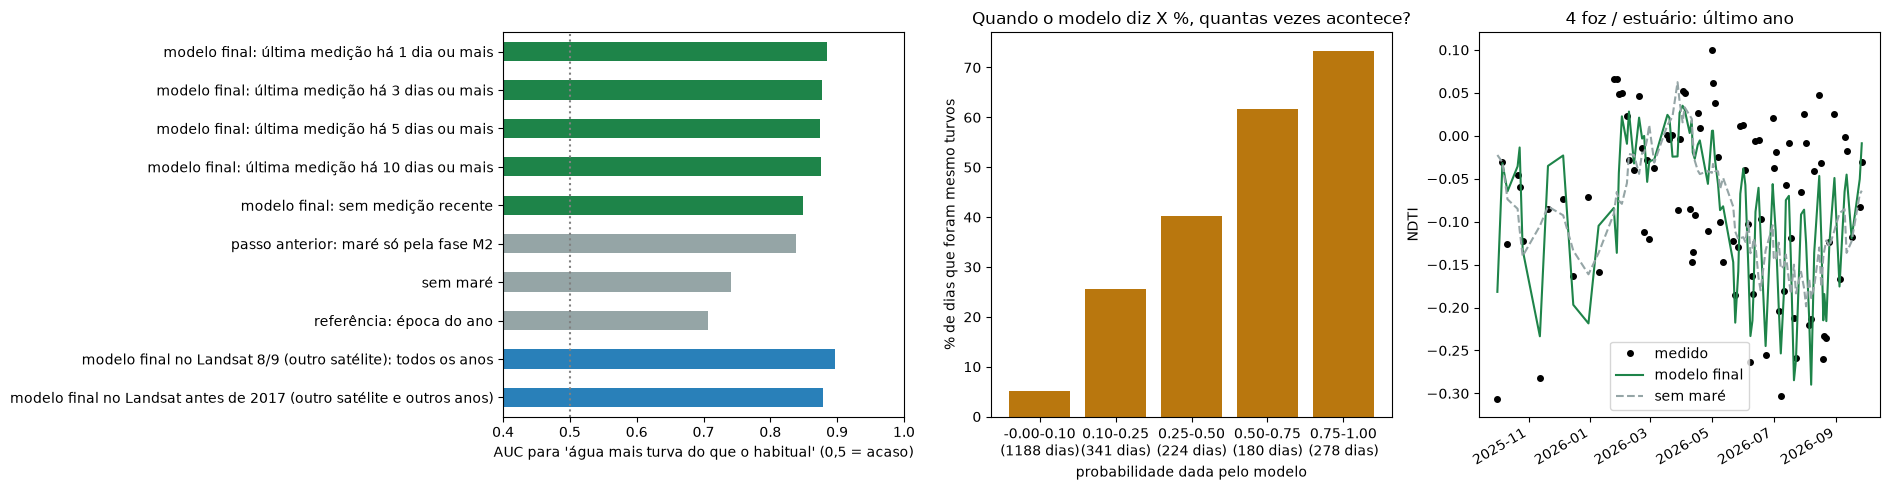

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
colour = ["#1e8449" if n.startswith("modelo final:") else "#2980b9" if "Landsat" in n else "#95a5a6" for n in skill.index]
skill["auc"].plot.barh(ax=axes[0], color=colour); axes[0].invert_yaxis(); axes[0].axvline(0.5, color="grey", linestyle=":")
axes[0].set_xlim(0.4, 1); axes[0].set_ylabel(""); axes[0].set_xlabel("AUC para 'água mais turva do que o habitual' (0,5 = acaso)")
bins = pd.cut(days["prob_modelo_5d"], [0, 0.1, 0.25, 0.5, 0.75, 1.0], include_lowest=True)
rel = days.groupby(bins, observed=True)["elevada"].agg(["mean", "size"])
axes[1].bar(range(len(rel)), 100 * rel["mean"], color="#b9770e")
axes[1].set_xticks(range(len(rel)), [f"{i.left:.2f}-{i.right:.2f}\n({n} dias)" for i, n in zip(rel.index, rel["size"])])
axes[1].set_xlabel("probabilidade dada pelo modelo"); axes[1].set_ylabel("% de dias que foram mesmo turvos"); axes[1].set_title("Quando o modelo diz X %, quantas vezes acontece?")
one = days[(days["troco"] == days["troco"].max()) & (days["date"] >= "2025-10-01")].set_index("date")
one["ndti"].plot(ax=axes[2], style="o", color="black", markersize=4, label="medido"); one["ndti_modelo_5d"].plot(ax=axes[2], color="#1e8449", label="modelo final")
one["ndti_sem"].plot(ax=axes[2], color="#95a5a6", linestyle="--", label="sem maré"); axes[2].legend(); axes[2].set_ylabel("NDTI")
axes[2].set_title(f"{days['troco'].max()}: último ano"); axes[2].set_xlabel("")
plt.tight_layout(); plt.savefig(REPORTS / "35_modelo_com_mare.png", dpi=110)
per_reach = pd.DataFrame({reach: {"dias": len(g), "r2": 1 - ((g["ndti"] - g["ndti_modelo_5d"]) ** 2).sum() / ((g["ndti"] - g["ndti"].mean()) ** 2).sum()}
                          for reach, g in days.groupby("troco")}).T
per_reach.round(3).to_csv(REPORTS / "35_modelo_por_troco.csv")
display(per_reach.round(3))
skill.round(3)

**Como ler a tabela**

- `r2`: parte da variação da cor da água que o modelo explica.
- `auc`: ao comparar um dia turvo com um dia normal, em quantos casos o modelo dá
  maior probabilidade ao dia turvo (0,5 = acaso; 1 = sempre).
- `bss`: quanto o modelo reduz o erro da probabilidade face à época do ano.
- As quatro primeiras linhas são o modelo final, conforme a idade da última
  medição. Quanto mais recente a medição, melhor. A linha "sem medição recente"
  é o que o modelo vale quando há mais de 30 dias de nuvens.
- As linhas a cinzento são os passos anteriores, para se ver de onde vem o ganho.
- As duas últimas linhas são o teste mais exigente: o modelo foi treinado só com
  o Sentinel-2 e é posto a prever os dias medidos pelo **Landsat**, outro
  satélite. Na última, além de outro satélite, são **outros anos** (2013 a 2016,
  antes de o Sentinel-2 existir), e a "última medição" é também do Landsat.

**As métricas são boas?** Para um indicador ambiental obtido só por satélite,
são sólidas: o modelo explica cerca de dois terços da variação, acerta a ordem
entre um dia turvo e um dia normal em quase 9 de cada 10 casos, e mantém o
desempenho num sensor e em anos que nunca viu, o que afasta a hipótese de ter
decorado os dados. Não são métricas de um instrumento de medição: cerca de um
terço da variação fica por explicar. O troço médio é o mais difícil. No gráfico
do meio vê-se também que, nas probabilidades mais altas, o modelo é um pouco
confiante demais: quando diz mais de 75 %, a água esteve mesmo turva em cerca de
três de cada quatro dias.

## 8. Teste 7: o que foi experimentado e não entrou

Foram testadas mais entradas, com o mesmo teste (ano deixado de fora). A regra,
decidida antes: uma entrada só fica se melhorar a probabilidade de "turbidez
elevada" (AUC ou erro da probabilidade), porque é isso que o boletim mostra, e
cada entrada a mais é mais uma coisa que pode falhar em produção.

O teste demora cerca de 15 minutos e corre à parte:
`.venv/bin/python scripts/experimento_turbidez_entradas.py`

In [10]:
tested = pd.read_csv(REPORTS / "35_entradas_testadas.csv", index_col=0)
tested["ganho_r2"], tested["ganho_auc"] = tested["r2"] - tested["r2"].iloc[0], tested["auc"] - tested["auc"].iloc[0]
tested.round(3)

,r2,auc,brier,ganho_r2,ganho_auc
entradas,,,,,
modelo final,0.657,0.872,0.126,0.000,0.000
+ vento na foz,0.674,0.875,0.124,0.017,0.003
+ chuva local na foz,0.654,0.872,0.126,-0.003,0.000
+ chuva por parte da bacia,0.656,0.874,0.124,-0.001,0.002
treinado com os dois satélites,0.664,0.874,0.122,0.007,0.002


**Leitura.** Nenhuma destas entradas melhora a probabilidade de forma que se
note. O vento explica um pouco mais da variação do índice (`r2`), mas não muda o
acerto da previsão "vai estar mais turva". Treinar com os dois satélites juntos
também não ajuda; o Landsat fica melhor empregue como teste independente e como
fonte da última medição. Ficam todas de fora.

**E o troço a montante?** Com a regra "só contam as imagens que viram pelo menos
metade do troço", os dois satélites concordam melhor (tabela seguinte), mas menos
do que nos outros troços. O modelo, experimentado nesse troço, explicou apenas
cerca de 20 % da variação. Continua com a medição marcada como de fiabilidade
reduzida e sem previsão. O notebook 34 mostra uma causa provável: é o único
troço com vegetação sobre a água.

In [11]:
rows = []
for reach in sorted(s2["troco"].unique()):
    a, b = s2[s2["troco"] == reach], ls[ls["troco"] == reach]
    m = a.merge(b, on="date", suffixes=("", "_landsat"))
    for share in (0.0, 0.5, 0.7):
        keep = (m["pixeis"] >= share * a["pixeis"].quantile(0.95)) & (m["pixeis_landsat"] >= share * b["pixeis"].quantile(0.95))
        rows.append({"troco": reach, "parte_do_troço_vista": f"pelo menos {share:.0%}" if share else "qualquer", "pares": int(keep.sum()),
                     "correlação": np.corrcoef(m.loc[keep, "ndti"], m.loc[keep, "ndti_landsat"])[0, 1]})
coverage = pd.DataFrame(rows).pivot(index="troco", columns="parte_do_troço_vista", values="correlação")[["qualquer", "pelo menos 50%", "pelo menos 70%"]]
coverage.round(2).to_csv(REPORTS / "35_ndti_entre_satelites_por_cobertura.csv")
coverage.round(2)

parte_do_troço_vista,qualquer,pelo menos 50%,pelo menos 70%
troco,,,
1 montante (norte),0.740,0.840,0.860
2 troço médio,0.940,0.950,0.950
3 jusante,0.950,0.950,0.950
4 foz / estuário,0.920,0.920,0.930


## Limites do modelo, a dizer sempre

- Prevê a cor da água **à hora de passagem do satélite** (cerca das 9h30 locais).
  A maré faz a turbidez mudar ao longo do dia, e os satélites só veem essa hora.
- Prevê um **índice relativo**, não turbidez em unidades reais (secção 2).
- A maré é **calculada**, a partir de um modelo do nível do mar na Baía de Maputo,
  não de um marégrafo. As constantes são fixas: a variação lenta da maré ao longo
  de 18,6 anos não está incluída. Não inclui o efeito do vento e da pressão no
  nível do mar.
- Depende de a série de imagens estar atualizada
  (`scripts/update_water_quality_scenes.py`). Sem imagem nos últimos 30 dias, o
  modelo continua a funcionar, com menos acerto (linha "sem medição recente").
- O troço a montante fica sem previsão.

## Decisão para a plataforma

1. **A medição** de cada troço: mediana das imagens dos últimos 20 dias.
2. **A previsão** para as manhãs dos próximos 10 dias, com o modelo final
   (caudal, chuva, época do ano, maré completa e última medição), nos três
   troços em que a medição é fiável.
3. A tabela por nível de caudal (secção 4) fica como explicação simples do
   efeito das cheias.

## O que se pode dizer em público

| Afirmação | Pode dizer-se? | Base |
|---|---|---|
| "Medimos a cor da água do Incomáti por satélite, a cada 5 dias quando não há nuvens" | sim | secção 1 |
| "A medição é repetível: dois satélites independentes concordam" | sim | secção 3 |
| "A água fica mais turva quando o rio sobe, e sabemos quanto" | sim | secção 4 |
| "A cor da água no troço final do rio segue a maré" | sim | secções 6 e 7 |
| "Prevemos, para os próximos dias, as manhãs em que a água deve estar mais turva, com acerto medido" | sim, com os limites acima | secção 7 |
| "A turbidez é de X FNU" | **não** como medição; só "cerca de X, estimativa" em páginas técnicas | secção 2 e notebook 29 (a versão com a banda do vermelho concorda melhor entre satélites, mas não tem calibração local) |
| "A água é (ou não é) segura" | **não** | a cor não mostra bactérias nem químicos |
| "Detetamos algas" | **não** | notebook 34: o índice de clorofila é dominado pelos sedimentos |

**O passo que falta para subir de nível:** amostras de turbidez recolhidas no rio
em dias de passagem do satélite (20 a 30 chegam para começar). Com elas, o índice
pode ser convertido em unidades reais e este notebook volta a ser corrido. O
protocolo está em `docs/protocolo_de_campo_qualidade_da_agua.md`.